# 03 - Event-driven loop: análises disparadas por eventos

Nos notebooks anteriores, a análise começava quando alguém chamava `executar()`. No **event-driven loop**, o loop espera eventos e reage a cada um. Quem dispara a análise é o evento, não uma chamada direta.

Um evento é uma mensagem com três partes:

- **tipo**: o que aconteceu, como `preco_atualizado`, `alerta_climatico` ou `analise_solicitada`;
- **origem**: quem emitiu, como um simulador de mercado ou um analista humano;
- **dados**: o conteúdo, como a praça e a variação de preço.

Os eventos passam por uma **fila**. Os produtores só colocam eventos nela, e o loop consome um de cada vez. Quem produz e quem consome não se conhecem.

Fluxo:

```
fontes (simuladores ou pessoa) → fila de eventos → loop → filtro do evento → análise → verificação → resultado
                                                          ↳ evento irrelevante: ignorado
```

Neste notebook:

1. **Como simular um evento:** os simuladores são funções que emitem eventos na fila, no lugar de um sistema externo (cotação, estação meteorológica).
2. **Como alguém pede uma análise manualmente:** um analista humano emite um evento `analise_solicitada` com a pergunta. Ele entra na mesma fila, e o loop trata do mesmo jeito.
3. **Análise:** cada evento vira uma análise com o mesmo grafo do notebook 02: analista, verificador e nova tentativa se reprovar.
4. **Erro intencional:** como no notebook 02, a primeira análise sai com um erro de propósito para o verificador ter o que corrigir.

Em produção, a fila seria um broker, como Kafka ou RabbitMQ, e os eventos chegariam por webhook, cron ou formulário. Aqui a fila é um `queue.Queue` na memória, para o foco ficar no loop.

Os dados continuam simulados, e o tema é o mesmo: preço do milho.

## 1. Configuração

A chave e o modelo vêm do `.env` na raiz do projeto, como nos outros notebooks.

O rastreamento usa o MLflow com um banco SQLite, `mlflow.db`, criado na pasta deste notebook. O loop inteiro vira um trace, com as análises e as passagens pelo `analista` e pelo `verificador`.

In [1]:
import json
import os
import queue
import itertools
import re
import unicodedata
from dataclasses import dataclass
from typing import TypedDict

from dotenv import find_dotenv, load_dotenv
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field
from IPython.display import Markdown, display
from IPython.display import Image

import mlflow

from deepagents import create_deep_agent

load_dotenv(find_dotenv())

mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENTO = "event-driven-milho"
experimento = mlflow.set_experiment(EXPERIMENTO)
mlflow.langchain.autolog()

llm = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-5-mini"),
    api_key=os.getenv("OPENAI_API_KEY"),
)

## 2. Dados simulados e ferramentas

Mesmos dados e ferramentas do notebook 02: preço, clima e estoques.

In [2]:
PRECOS_SACA = {
    "paranagua": {"praca": "Paranaguá (PR)", "preco_rs_saca": 118.50, "variacao_7_dias_pct": 1.8},
    "cascavel": {"praca": "Cascavel (PR)", "preco_rs_saca": 112.30, "variacao_7_dias_pct": 2.4},
    "rio verde": {"praca": "Rio Verde (GO)", "preco_rs_saca": 108.90, "variacao_7_dias_pct": 0.6},
    "campinas": {"praca": "Campinas (SP)", "preco_rs_saca": 120.10, "variacao_7_dias_pct": -0.9},
}

CLIMA = {
    "parana": {"regiao": "Oeste do Paraná", "chuva_ultimos_7_dias_mm": 12, "chuva_prevista_15_dias_mm": 18,
               "risco": "baixo", "observacao": "Chuva irregular no fim do mês, sem sinal de seca forte."},
    "mato grosso": {"regiao": "Mato Grosso", "chuva_ultimos_7_dias_mm": 4, "chuva_prevista_15_dias_mm": 6,
                    "risco": "alto", "observacao": "Veranico prolongado, risco de perda na segunda safra."},
    "goias": {"regiao": "Goiás", "chuva_ultimos_7_dias_mm": 7, "chuva_prevista_15_dias_mm": 10,
              "risco": "médio", "observacao": "Chuva abaixo da média para a época."},
}

ESTOQUES = {
    "safra_estimada_mil_t": 128_000,
    "consumo_estimado_mil_t": 79_000,
    "estoque_inicial_mil_t": 21_000,
    "exportacao_estimada_mil_t": 42_000,
    "estoque_final_estimado_mil_t": 28_000,
    "relacao_estoque_consumo_pct": 35.4,
    "leitura": "Estoque final abaixo da média dos últimos 5 anos.",
}


@tool
def consultar_preco_milho(praca: str) -> str:
    """Consulta o preço spot do milho em uma praça. Praças válidas: paranagua, cascavel, rio verde, campinas."""
    chave = praca.lower().strip()
    if chave not in PRECOS_SACA:
        return json.dumps({"erro": f"Praça '{praca}' não encontrada.", "pracas_validas": list(PRECOS_SACA)}, ensure_ascii=False)
    return json.dumps(PRECOS_SACA[chave], ensure_ascii=False)


@tool
def consultar_clima(regiao: str) -> str:
    """Consulta a chuva recente, a previsão e o risco climático de uma região produtora. Regiões válidas: parana, mato grosso, goias."""
    chave = regiao.lower().strip()
    if chave not in CLIMA:
        return json.dumps({"erro": f"Região '{regiao}' não encontrada.", "regioes_validas": list(CLIMA)}, ensure_ascii=False)
    return json.dumps(CLIMA[chave], ensure_ascii=False)


@tool
def consultar_estoques() -> str:
    """Consulta o balanço de oferta e demanda do milho no Brasil: safra, consumo, exportação e estoque final."""
    return json.dumps(ESTOQUES, ensure_ascii=False)


FERRAMENTAS = [consultar_preco_milho, consultar_clima, consultar_estoques]

## 3. Analista e verificador

O analista é o deep agent dos notebooks anteriores. A diferença é que a pergunta agora vem do evento, por isso ela entra no estado do grafo.

O erro intencional é o mesmo do notebook 02: um valor em R$ é trocado por um 10% maior depois que o agente responde. Ele só é aplicado quando a flag `injetar_erro` está ligada, e só na primeira tentativa da análise.

O verificador é o mesmo do notebook 02: regras determinísticas e juiz com LLM.

In [3]:
agente = create_deep_agent(
    model=llm,
    tools=FERRAMENTAS,
    system_prompt=(
        "Você é um analista do mercado de milho. "
        "Antes de concluir, use as ferramentas para reunir os dados: preços em pelo menos duas praças, "
        "o clima de pelo menos uma região produtora e o balanço de estoques. "
        "Quando tiver os dados, escreva em português um relatório curto com as seções: "
        "situação dos preços, risco climático, leitura dos estoques e recomendação (vender, comprar ou aguardar), "
        "com a justificativa. Use somente valores que vieram das ferramentas. Lembre que os dados são simulados."
    ),
)

MAX_TENTATIVAS = 3
ERRO_INTENCIONAL = True


def introduzir_erro(relatorio: str) -> str:
    # troca o primeiro valor em R$ por um 10% maior
    # se o relatório não tiver valor em R$, acrescenta uma frase com um preço errado
    erro = []

    def trocar(m):
        valor = converter_valor(m.group(1)) * 1.1
        erro.append(valor)
        return f"R$ {valor:.2f}".replace(".", ",")

    novo = re.sub(r"R\$\s?(\d+(?:[.,]\d+)*)", trocar, relatorio, count=1)
    if not erro:
        valor_br = f"{PRECOS_SACA['cascavel']['preco_rs_saca'] * 1.1:.2f}".replace(".", ",")
        novo = f"Situação dos preços: Cascavel (PR) a R$ {valor_br} por saca.\n\n" + novo
    return novo


class Estado(TypedDict):
    pergunta: str
    relatorio: str
    evidencias: list[str]
    tentativas: int
    feedback: str
    verificacao: dict
    injetar_erro: bool


def analista(estado: Estado) -> dict:
    pergunta = estado["pergunta"]
    if estado.get("feedback"):
        pergunta += (
            "\n\nA verificação do relatório anterior reprovou. Este era o relatório anterior:\n"
            f"{estado['relatorio']}\n\n"
            f"Corrija os problemas abaixo e refaça o relatório, usando somente dados das ferramentas:\n"
            f"{estado['feedback']}"
        )

    resultado = agente.invoke({"messages": [HumanMessage(content=pergunta)]})
    mensagens = resultado["messages"]
    relatorio = mensagens[-1].content
    if estado.get("injetar_erro") and estado.get("tentativas", 0) == 0:
        relatorio = introduzir_erro(relatorio)
        print("    [demonstração] o analista errou de propósito na primeira tentativa")
    return {
        "relatorio": relatorio,
        "evidencias": [m.content for m in mensagens if isinstance(m, ToolMessage)],
        "tentativas": estado.get("tentativas", 0) + 1,
    }

In [4]:
SECOES_OBRIGATORIAS = {
    "preços": ["preco", "precos"],
    "clima": ["clima", "climatic", "chuva"],
    "estoques": ["estoque"],
    "recomendação": ["recomend"],
}


def sem_acento(texto: str) -> str:
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto if not unicodedata.combining(c)).lower()


def converter_valor(texto: str) -> float:
    # aceita o formato brasileiro (1.250,40) e o formato com ponto decimal (118.5)
    if "," in texto:
        return float(texto.replace(".", "").replace(",", "."))
    return float(texto)


def regras_deterministicas(relatorio: str, evidencias: list[str]) -> list[str]:
    problemas = []
    texto = sem_acento(relatorio)

    for secao, termos in SECOES_OBRIGATORIAS.items():
        if not any(termo in texto for termo in termos):
            problemas.append(f"Falta a seção sobre {secao}.")

    dados = " ".join(evidencias)
    numeros_dados = {round(float(n), 2) for n in re.findall(r"\d+\.\d+", dados)}
    for valor_texto in re.findall(r"R\$\s?(\d+(?:[.,]\d+)*)", relatorio):
        valor = round(converter_valor(valor_texto), 2)
        if valor not in numeros_dados:
            problemas.append(f"O valor R$ {valor_texto} não aparece nos dados das ferramentas.")

    return problemas

In [5]:
class Avaliacao(BaseModel):
    aprovado: bool = Field(description="True se todas as afirmações têm apoio nas evidências e a recomendação é justificada.")
    problemas: list[str] = Field(description="Problemas concretos encontrados. Lista vazia se aprovado.")


juiz = llm.with_structured_output(Avaliacao)


def verificador(estado: Estado) -> dict:
    problemas = regras_deterministicas(estado["relatorio"], estado["evidencias"])

    if not problemas:
        evidencias = "\n".join(estado["evidencias"])
        avaliacao = juiz.invoke([
            SystemMessage(content=(
                "Você revisa relatórios de mercado. Aprove somente se cada afirmação tiver apoio nas evidências, "
                "se nenhum dado foi inventado e se a recomendação for justificada pelos dados. "
                "Se reprovar, liste problemas concretos e curtos."
            )),
            HumanMessage(content=f"Evidências das ferramentas:\n{evidencias}\n\nRelatório:\n{estado['relatorio']}"),
        ])
        problemas = [] if avaliacao.aprovado else (avaliacao.problemas or ["Juiz reprovou sem apontar motivo."])

    return {
        "verificacao": {"aprovado": not problemas, "problemas": problemas},
        "feedback": "\n".join(f"- {p}" for p in problemas),
    }

## 4. Grafo de análise

É o mesmo grafo do notebook 02: o analista leva ao verificador, e a aresta condicional volta ao analista se reprovar, até o limite de tentativas.

In [6]:
def decidir(estado: Estado) -> str:
    if estado["verificacao"]["aprovado"]:
        return END
    if estado["tentativas"] >= MAX_TENTATIVAS:
        return END
    return "analista"


grafo = StateGraph(Estado)
grafo.add_node("analista", analista)
grafo.add_node("verificador", verificador)
grafo.add_edge(START, "analista")
grafo.add_edge("analista", "verificador")
grafo.add_conditional_edges("verificador", decidir, {"analista": "analista", END: END})
app = grafo.compile()

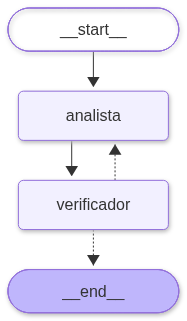

In [7]:
display(Image(app.get_graph().draw_mermaid_png()))

## 5. Eventos e fila

Um evento é um `dataclass` com `id`, `tipo`, `origem` e `dados`. A fila é um `queue.Queue`: `emitir` coloca um evento nela, e o loop tira da fila.

Nesta célula está só a infraestrutura. Os simuladores e o pedido manual ficam na célula seguinte.

In [8]:
@dataclass
class Evento:
    id: int
    tipo: str
    origem: str
    dados: dict


FILA = queue.Queue()
IDS = itertools.count(1)


def emitir(tipo: str, origem: str, **dados) -> Evento:
    evento = Evento(next(IDS), tipo, origem, dados)
    FILA.put(evento)
    print(f"evento {evento.id} emitido: {tipo} (origem: {origem})")
    return evento

## 6. Como simular um evento

Um simulador é uma função que emite eventos. Ela troca uma fonte externa, como uma cotação de preço ou uma estação meteorológica. O loop não sabe se o evento veio de um simulador ou de um sistema real. Ele só vê a fila.

Também tem o **pedido manual**: uma pessoa pede uma análise emitindo um evento `analise_solicitada`. Em um notebook, isso é uma chamada de função. Em um sistema real, seria um formulário, um chat ou uma API. O resultado é o mesmo: um evento na fila.

In [9]:
def simular_variacao_preco(praca: str, variacao_pct: float) -> Evento:
    return emitir("preco_atualizado", "simulador_mercado", praca=praca, variacao_pct=variacao_pct)


def simular_alerta_clima(regiao: str, risco: str) -> Evento:
    return emitir("alerta_climatico", "simulador_clima", regiao=regiao, risco=risco)


def solicitar_analise(pergunta: str, usuario: str = "analista_humano") -> Evento:
    return emitir("analise_solicitada", usuario, pergunta=pergunta)

## 7. Filtro e pergunta de cada evento

Nem todo evento vira análise. Uma variação de preço abaixo do limiar é ignorada. Os outros tipos viram uma pergunta para o analista. O pedido manual já traz a pergunta pronta.

In [10]:
LIMIAR_PRECO_PCT = 2.0


def montar_pergunta(evento: Evento) -> str | None:
    dados = evento.dados
    if evento.tipo == "preco_atualizado":
        if abs(dados["variacao_pct"]) < LIMIAR_PRECO_PCT:
            return None
        return (
            f"O preço do milho na praça {dados['praca']} variou {dados['variacao_pct']}% recentemente. "
            "Analise o impacto para um produtor do Paraná e recomende uma ação."
        )
    if evento.tipo == "alerta_climatico":
        return (
            f"Há alerta climático na região {dados['regiao']} com risco {dados['risco']}. "
            "Analise o impacto sobre os preços e os estoques e recomende uma ação."
        )
    if evento.tipo == "analise_solicitada":
        return dados["pergunta"]
    raise ValueError(f"Tipo de evento desconhecido: {evento.tipo}")

## 8. Loop de eventos

O loop tira um evento da fila por vez. Se o evento não gera análise, ele é registrado como ignorado. Se gera, a análise roda com o grafo do notebook 02.

Só a primeira análise do loop recebe o erro intencional, como no notebook 02. As outras saem normalmente.

Aqui o loop drena a fila até ela esvaziar. Em um sistema contínuo, o mesmo loop ficaria bloqueado em `FILA.get()`, esperando o próximo evento.

In [11]:
@mlflow.trace(name="analise")
def analisar(pergunta: str, injetar_erro: bool = False) -> dict:
    estado = app.invoke(
        {"pergunta": pergunta, "tentativas": 0, "feedback": "", "injetar_erro": injetar_erro},
        config={"recursion_limit": 30},
    )
    estado["trace_id"] = mlflow.get_active_trace_id()
    return estado


@mlflow.trace(name="loop_eventos")
def loop_eventos() -> list[dict]:
    resultados = []
    analises_feitas = 0

    while not FILA.empty():
        evento = FILA.get()
        pergunta = montar_pergunta(evento)

        if pergunta is None:
            print(f"evento {evento.id} ({evento.tipo}): ignorado, abaixo do limiar")
            resultados.append({"evento": evento, "status": "ignorado", "tentativas": 0, "relatorio": ""})
            continue

        injetar = ERRO_INTENCIONAL and analises_feitas == 0
        analises_feitas += 1
        print(f"evento {evento.id} ({evento.tipo}): iniciando análise")
        estado = analisar(pergunta, injetar_erro=injetar)

        status = "aprovado" if estado["verificacao"]["aprovado"] else "entregue com ressalvas"
        print(f"    status: {status} após {estado['tentativas']} tentativa(s)")
        resultados.append({
            "evento": evento,
            "status": status,
            "tentativas": estado["tentativas"],
            "relatorio": estado["relatorio"],
            "trace_id": estado["trace_id"],
        })

    return resultados

## 9. Disparando os eventos

Os três simuladores e o pedido manual colocam eventos na fila. Nada é analisado ainda: as análises começam só quando o loop roda, na célula seguinte.

- a variação de 0,4% no Paranaguá fica abaixo do limiar de 2%: será ignorada;
- a variação de 2,4% em Cascavel passa do limiar: será analisada;
- o alerta climático do Mato Grosso será analisado;
- o pedido manual de um analista humano será analisado.

In [12]:
simular_variacao_preco("paranagua", 0.4)
simular_variacao_preco("cascavel", 2.4)
simular_alerta_clima("mato grosso", "alto")
solicitar_analise("Vale a pena guardar milho no armazém até o fim do mês, ou vender agora?")

print(f"\nEventos na fila: {FILA.qsize()}")

evento 1 emitido: preco_atualizado (origem: simulador_mercado)
evento 2 emitido: preco_atualizado (origem: simulador_mercado)
evento 3 emitido: alerta_climatico (origem: simulador_clima)
evento 4 emitido: analise_solicitada (origem: analista_humano)

Eventos na fila: 4


## 10. Rodando o loop

O loop consome a fila até esvaziar. A tabela no fim resume cada evento.

In [13]:
resultados = loop_eventos()

print("\n--- Resumo ---")
print(f"{'id':>3}  {'tipo':<20} {'origem':<18} {'status':<24} tentativas")
for r in resultados:
    evento = r["evento"]
    print(f"{evento.id:>3}  {evento.tipo:<20} {evento.origem:<18} {r['status']:<24} {r['tentativas']}")

ultimo_relatorio = [r for r in resultados if r["status"] != "ignorado"][-1]
print(f"\n--- Relatório do último evento analisado (id {ultimo_relatorio['evento'].id}) ---")
print(ultimo_relatorio["relatorio"])

evento 1 (preco_atualizado): ignorado, abaixo do limiar
evento 2 (preco_atualizado): iniciando análise
    [demonstração] o analista errou de propósito na primeira tentativa
    status: aprovado após 3 tentativa(s)
evento 3 (alerta_climatico): iniciando análise
    status: aprovado após 1 tentativa(s)
evento 4 (analise_solicitada): iniciando análise
    status: aprovado após 2 tentativa(s)

--- Resumo ---
 id  tipo                 origem             status                   tentativas
  1  preco_atualizado     simulador_mercado  ignorado                 0
  2  preco_atualizado     simulador_mercado  aprovado                 3
  3  alerta_climatico     simulador_clima    aprovado                 1
  4  analise_solicitada   analista_humano    aprovado                 2

--- Relatório do último evento analisado (id 4) ---
Relatório curto — milho

1) Situação dos preços
- Paranaguá (PR): R$ 118,50/saca; variação últimos 7 dias: +1,8%.
- Rio Verde (GO): R$ 108,90/saca; variação últimos 7 di

## 11. Acompanhando o loop no MLflow

O loop inteiro virou um trace no experimento `event-driven-milho`. Dentro dele, cada análise aparece como uma passagem pelo `analista` e pelo `verificador`.

Para abrir a interface:

1. Abra um terminal na pasta `notebooks/05-LoopEngineering`.
2. Rode:

```bash
uv run --project ../.. mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

3. Abra `http://127.0.0.1:5000`, escolha o experimento `event-driven-milho` e abra a aba **Traces**.
4. Pressione `Ctrl+C` para parar a interface.

A célula seguinte lê o trace pelo notebook.

In [14]:
mlflow.flush_trace_async_logging()  # garante que os traces já foram gravados

analisados = [r for r in resultados if r["status"] != "ignorado"]
trace = mlflow.get_trace(analisados[0]["trace_id"])
nomes_nos = [s.name for s in trace.data.spans if s.name in ("analista", "verificador")]
print(f"Trace do loop ({trace.info.trace_id}):")
print(" → ".join(nomes_nos))

Trace do loop (tr-06cc2d5b285e860461aaf232c0646708):
analista → verificador → analista → verificador → analista → verificador → analista → verificador → analista → verificador → analista → verificador


## Observações

- Quem produz evento não conhece quem consome. Um simulador, um sistema externo ou uma pessoa só colocam mensagens na fila.
- O filtro decide o que vira trabalho. O evento de 0,4% foi ignorado sem gastar uma chamada ao modelo.
- Pedido manual e evento automático seguem o mesmo caminho. Isso facilita auditar: todo pedido, de qualquer origem, aparece na fila com origem e horário de emissão.
- O loop consome a fila até esvaziar, o que é útil para um teste. Em produção, ele fica bloqueado esperando eventos e precisa de limite de tentativas e de tratamento de falha por evento.
- O erro intencional continua sendo só uma demonstração. Para desligar, troque `ERRO_INTENCIONAL` para `False`.